In [1]:
import numpy as np
import numpy.ma as ma
import xarray as xr
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.patches import Rectangle
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
#my own classes
import sys
sys.path.append("/Users/michelefilippucci/Prog/github/blocktrack/lib")
import blocktoolbox as BT

In [2]:
%cd /Users/michelefilippucci/Data/ERA5/gr_tracking/dictionaries/
!ls 

# Enable interactive mode in Jupyter notebook
#%matplotlib ipympl

/Users/michelefilippucci/Data/ERA5/gr_tracking/dictionaries
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_DIC.npy
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023_DIC.npy
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023_DIC.npy
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1940-2023_DIC.npy


In [3]:
dic = np.load("ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1940-2023_DIC.npy",allow_pickle=True)

In [4]:
dic[0] = dic[-1]

In [5]:
#PERSISTENCE
pers = []
for event in dic:
  pers.append(event['persistence'])

#AREA
area = []
for event in dic:
  area.append(event['avg_area'])

#TRACK
track = []
for i,event in enumerate(dic):
  track.append(event['track'])
'''
#ASPECT_RATIO
avg_aspect_ratio=[]
for event in dic:
  avg_aspect_ratio.append(event['avg_dist_traveled'])
'''
#MEAN DISTANCE TRAVELLED
dist = []
for event in dic:
  try:  
    dist.append(event['avg_dist_traveled'])
  except:
    print(event)  

#COLOR
color = []
c = ''
for l,event in enumerate(dic):
  try:
    xs,ys = event['track']
  except:
    print(l)
  if np.mean(xs) >= 65:
    c = 'r'
  elif 40 <= np.mean(xs) < 65:
    c = 'y'
  elif np.mean(xs) < 40:
    c = 'b'
  color.append(c)
'''

#COLOR
color = []
c = ''
threshold = 350
for event in dic:
  D = event['distance_traveled']
  if D>=threshold:
    c = 'red'
  elif D<threshold:
    c = 'blue'
  color.append(c)
'''

"\n\n#COLOR\ncolor = []\nc = ''\nthreshold = 350\nfor event in dic:\n  D = event['distance_traveled']\n  if D>=threshold:\n    c = 'red'\n  elif D<threshold:\n    c = 'blue'\n  color.append(c)\n"

In [6]:
dic[-3]

{'persistence': 6,
 'avg_area': 3469457.7190730665,
 'avg_aspect_ratio': 8.853798029602556,
 'distance_traveled': 2600.040217657314,
 'track': ([48.52272727272727,
   48.94366197183099,
   48.117283950617285,
   46.61616161616162,
   46.21621621621622,
   46.416666666666664],
  [179.14772727272725,
   -169.7887323943662,
   -164.75308641975312,
   -163.93939393939394,
   -157.97297297297297,
   -148.0]),
 'date': numpy.datetime64('2023-11-11T06:00:00.000000000'),
 'time': 30630,
 'intensity': 1994.7134707773932,
 'avg_dist_traveled': 433.340036276219}

3330.837086474996 0.0 nan


/Users/michelefilippucci/miniconda3/envs/blocktoolbox_env/lib/python3.11/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/michelefilippucci/miniconda3/envs/blocktoolbox_env/lib/python3.11/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


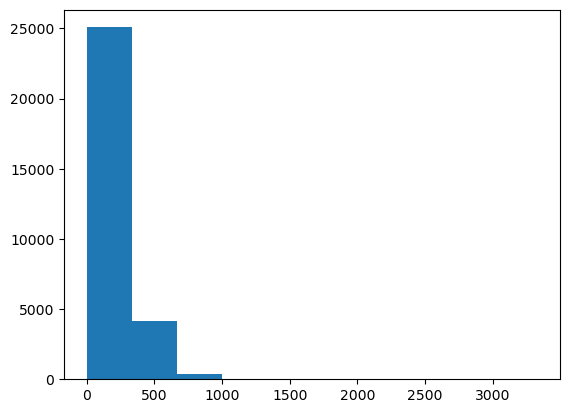

In [7]:
plt.hist(dist)
coordinate_p = []
for i,a in enumerate(area):
    if a == 0:
        print(pers[i])
        coordinate_p.append(track[i][1][0])
print(np.amax(dist),np.amin(dist),np.mean(coordinate_p))

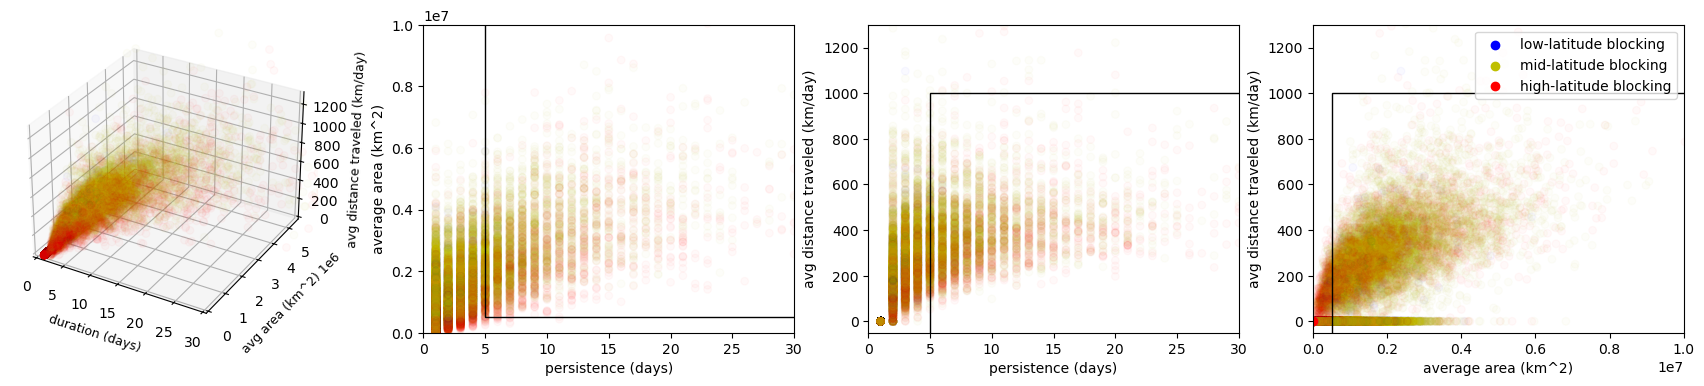

29600


In [8]:
fig = plt.figure(figsize=(22,4))

size=30
alpha=0.025
alpha_cube = 0.1
alpha_square=1
face_color = 'grey'

#3D scatter plot
ax = fig.add_subplot(141, projection='3d')
ax.scatter(pers, np.array(area)/1e6, dist,alpha=alpha,c = color,s=size)
ax.set_xlabel('duration (days)',fontsize=9)
ax.set_ylabel('avg area (km^2) 1e6',loc='top',fontsize=9)
ax.set_zlabel('avg distance traveled (km/day)',fontsize=9)
ax.set_xlim(0, 30)  # Set x-axis range
ax.set_ylim(0, 5.5)  # Set y-axis range
ax.set_zlim(0, 1300)  # Set z-axis range
# Define cube vertices
min_pers = 5
max_pers = 300 #np.amax(pers)
min_area = 500000/1e6
max_area = 1000000000/1e6#np.amax(area)
min_ext = -100
max_ext = 1000
cube_vertices = [
    [min_pers, min_area, min_ext],
    [max_pers, min_area, min_ext],
    [max_pers, max_area, min_ext],
    [min_pers, max_area, min_ext],
    [min_pers, min_area, max_ext],
    [max_pers, min_area, max_ext],
    [max_pers, max_area, max_ext],
    [min_pers, max_area, max_ext],
]
cube_faces = [
    [cube_vertices[0], cube_vertices[1], cube_vertices[2], cube_vertices[3]],
    [cube_vertices[4], cube_vertices[5], cube_vertices[6], cube_vertices[7]],
    [cube_vertices[0], cube_vertices[1], cube_vertices[5], cube_vertices[4]],
    [cube_vertices[2], cube_vertices[3], cube_vertices[7], cube_vertices[6]],
    [cube_vertices[0], cube_vertices[3], cube_vertices[7], cube_vertices[4]],
    [cube_vertices[1], cube_vertices[2], cube_vertices[6], cube_vertices[5]],
]
cube = Poly3DCollection(cube_faces, alpha=alpha_cube, facecolors=face_color, edgecolors='grey')
#ax.add_collection3d(cube)
#ax.set_title('a')

min_area = min_area*1e6
max_area = max_area*1e6#np.amax(area)

#XY projection
ax2d = fig.add_subplot(142)
ax2d.scatter(pers,area,alpha=alpha,c = color,s=size)
ax2d.set_xlim(0, 30)
ax2d.set_ylim(0, 10e6)
square = Rectangle((min_pers, min_area), max_pers-min_pers, max_area-min_area, alpha=alpha_square, edgecolor='black', fill = False)
ax2d.add_patch(square)
ax2d.set_xlabel('persistence (days)')
ax2d.set_ylabel('average area (km^2)')
#ax2d.set_title('b')

#XZ projection
ax2d = fig.add_subplot(143)
ax2d.scatter(pers,dist,alpha=alpha,c = color,s=size)
ax2d.set_xlim(0, 30)
ax2d.set_ylim(-50, 1300)
square = Rectangle((min_pers, min_ext), max_pers-min_pers, max_ext-min_ext, alpha=alpha_square, edgecolor='black', fill = False)
ax2d.add_patch(square)
ax2d.set_xlabel('persistence (days)')
ax2d.set_ylabel('avg distance traveled (km/day)')
#ax2d.set_title('c')


#YZ projection
ax2d = fig.add_subplot(144)
ax2d.scatter(area,dist,alpha=alpha,c = color,s=size)
#FAKE SCATTER PLOT TO SET THE LABELS
ax2d.scatter(0,0,c='b',label='low-latitude blocking')
ax2d.scatter(0,0,c='y',label='mid-latitude blocking')
ax2d.scatter(0,0,c='r',label='high-latitude blocking')
ax2d.set_xlim(0, 10e6)
ax2d.set_ylim(-50, 1300)
square = Rectangle((min_area, min_ext), max_area-min_area, max_ext-min_ext, alpha=alpha_square, edgecolor='black', fill = False)
ax2d.add_patch(square)
ax2d.set_xlabel('average area (km^2)')
ax2d.set_ylabel('avg distance traveled (km/day)')
#ax2d.set_title('d')
ax2d.legend()


# Show the plot
plt.savefig("/Users/michelefilippucci/PLOTS/pres_exeter/scatter_GHA.png",bbox_inches='tight',dpi = 400)
plt.show()
print(len(color))

#### Sarebbe interessante vedere se il longitudinal avg_aspect_ratio ha una dipendenza dalla latitudine.


inoltre sarebbe meglio usare delle 2d heatmaps invece degli scatter plots quando si passa in 2d

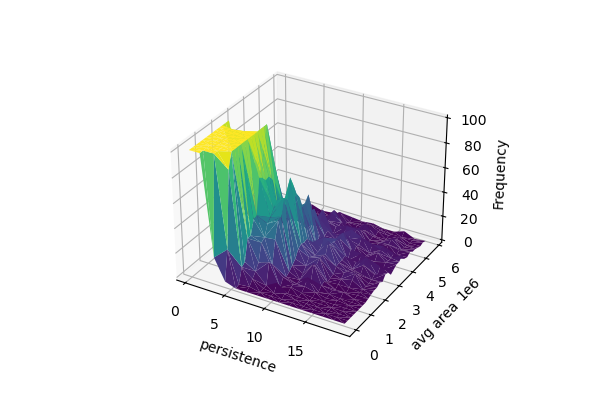

In [9]:
import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.mplot3d import Axes3D

# Enable interactive mode in Jupyter notebook
%matplotlib ipympl

x = pers
y = area
zlim = 100
range = [[0,20],[0,6e6]]
xlabel = 'persistence'
ylabel = 'avg area'

def hist3d(x,y,zlim,range,xlabel,ylabel):
  ax = fig.add_subplot(111, projection='3d')
  hist, xedges, yedges = np.histogram2d(x, y, bins=(15, 30),range=range)
  xpos, ypos = np.meshgrid(xedges[:-1] + 0.25, yedges[:-1] + 0.25, indexing="ij")
  xpos = xpos.ravel()
  ypos = ypos.ravel()
  zpos = np.zeros_like(xpos)
  dx = dy = 0.5
  dz = hist.ravel()
  dz = np.where(dz>zlim,zlim,dz)
  ax.plot_trisurf(xpos, ypos, dz, vmin=0, vmax=100,cmap='viridis')
  # Add labels and title
  ax.set_xlabel('persistence')
  ax.set_ylabel('avg area')
  ax.set_zlabel('Frequency')
  ax.set_zlim(0,zlim)
  return ax

fig = plt.figure(figsize=(6,4))
ax = hist3d(x,y,zlim,range,xlabel,ylabel)
plt.show()
